# SAT3 TGLF flux analysis

This notebook reads 43 TGLF runs of a tokamak plasma, finds which inputs each run changes from a baseline, and plots how the output fluxes respond. Each case is named `<letter>_<ion>`: the letter picks the experiment, and the ion is hydrogen (H), deuterium (D) or tritium (T). Fluxes are in gyro-Bohm units. It ends with a data-quality check and two CSVs written to `data/`. Run the cells from top to bottom.

## Step 1: imports

numpy, pandas, matplotlib and seaborn, plus `load_cases` from `tglf_dataset.py`, which does the file reading.

In [ ]:
# step 1: imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tglf_dataset import letter_ion_case_info, load_cases  # reads every case's input.tglf.gen + out.tglf.gbflux (tglf_dataset.py)

## Step 2: load the data

`load_cases` reads `input.tglf.gen` and `out.tglf.gbflux` for every case into one table, `df`, with a row per case. It parses all the inputs, labels each species as electron, H, D or T from its charge and mass, and takes the particle, heat and momentum flux of each species. A case with a missing file or a parse error is listed in `failures_df` instead of being skipped silently.

In [ ]:
# step 2: iterate through every case in the data directory and read it into a pandas dataframe (code in tglf_dataset.py)
# step 2.1: find every <letter1>_<letter2>/tglf_sat2 folder, with its input.tglf.gen and out.tglf.gbflux
# step 2.2: parse the inputs into one flat vector per case and infer species_type_n from ZS_n and MASS_n
# step 2.3: parse the particle / energy / toroidal momentum flux of each species from out.tglf.gbflux
# every case that is missing a file or fails to parse is reported in failures_df, never skipped silently

DATA_DIR = Path("SAT3_dataset/SAT3_dataset/data")
df, failures_df = load_cases(DATA_DIR, case_info=letter_ion_case_info)   # case_info adds letter1 / letter2 from names like a_D

print(f"parsed {len(df)} cases, {len(failures_df)} failed")
if len(failures_df):
    print("FAILED CASES:")
    for case, reason in failures_df.itertuples(index=False):
        print(f"  {case}: {reason}")
print(df.shape)
df.head()

## Step 3: find which inputs vary

Each case is compared with the baseline, the most common value of every input. `deltas_df` holds how far each case sits from that baseline and keeps only the inputs that change in at least one case. Of the roughly 180 inputs, 12 numeric ones change, plus the ion species.

In [19]:
# step 3: find features that matter. compare each case's inputs with the most common value of every column

FLUX_PREFIXES = ("particle_flux_", "energy_flux_", "momentum_flux_")
input_cols = [c for c in df.columns
              if not c.startswith(FLUX_PREFIXES) and c not in ("letter1", "letter2")]
most_common = df[input_cols].mode().iloc[0] # the most common value of each input column
numeric_cols = df[input_cols].select_dtypes("number").columns.tolist()
cat_cols = [c for c in input_cols if c not in numeric_cols]

cat_df = df[cat_cols].ne(most_common[cat_cols])
cat_df = cat_df.loc[:, cat_df.any()]   # keep columns that changed in at least one case

deltas_df = df[numeric_cols] - most_common[numeric_cols].astype(float)
deltas_df = deltas_df.loc[:, (deltas_df != 0).any()] # only keep columns that changed for at least one case

rel_df = deltas_df / most_common[deltas_df.columns].astype(float).abs()

summary = pd.DataFrame({
    "baseline": most_common[deltas_df.columns],
    "n_cases_changed": (deltas_df != 0).sum(),
    "min": df[deltas_df.columns].min(),
    "max": df[deltas_df.columns].max(),
}).sort_values("n_cases_changed", ascending=False)

all_changed = deltas_df.merge(cat_df, left_index=True, right_index=True, how="outer")
all_changed

,MASS_2,RLNS_1,RLNS_2,RLTS_1,RLTS_2,TAUS_2,XNUE,RMIN_LOC,DRMAJDX_LOC,KAPPA_LOC,Q_LOC,Q_PRIME_LOC,species_type_2
case,,,,,,,,,,,,,
a_D,0.0,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,False
a_H,-0.5,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,True
a_T,0.5,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,True
b_D,0.0,0.0,0.0,-1.50,-1.50,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,False
b_H,-0.5,0.0,0.0,-1.50,-1.50,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,True
b_T,0.5,0.0,0.0,-1.50,-1.50,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,True
c_D,0.0,0.0,0.0,-0.75,-0.75,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,False
c_H,-0.5,0.0,0.0,-0.75,-0.75,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,True
c_T,0.5,0.0,0.0,-0.75,-0.75,0.0,0.00,0.00,0.000,0.00,0.0,0.000000,True


## Step 4: explore the data

Plots and checks on the varying inputs and the output fluxes.

### Distributions

A histogram of every varying input and every flux, with the most common input value marked in red. Energy fluxes use a log axis. This cell also defines the display names the later plots use.

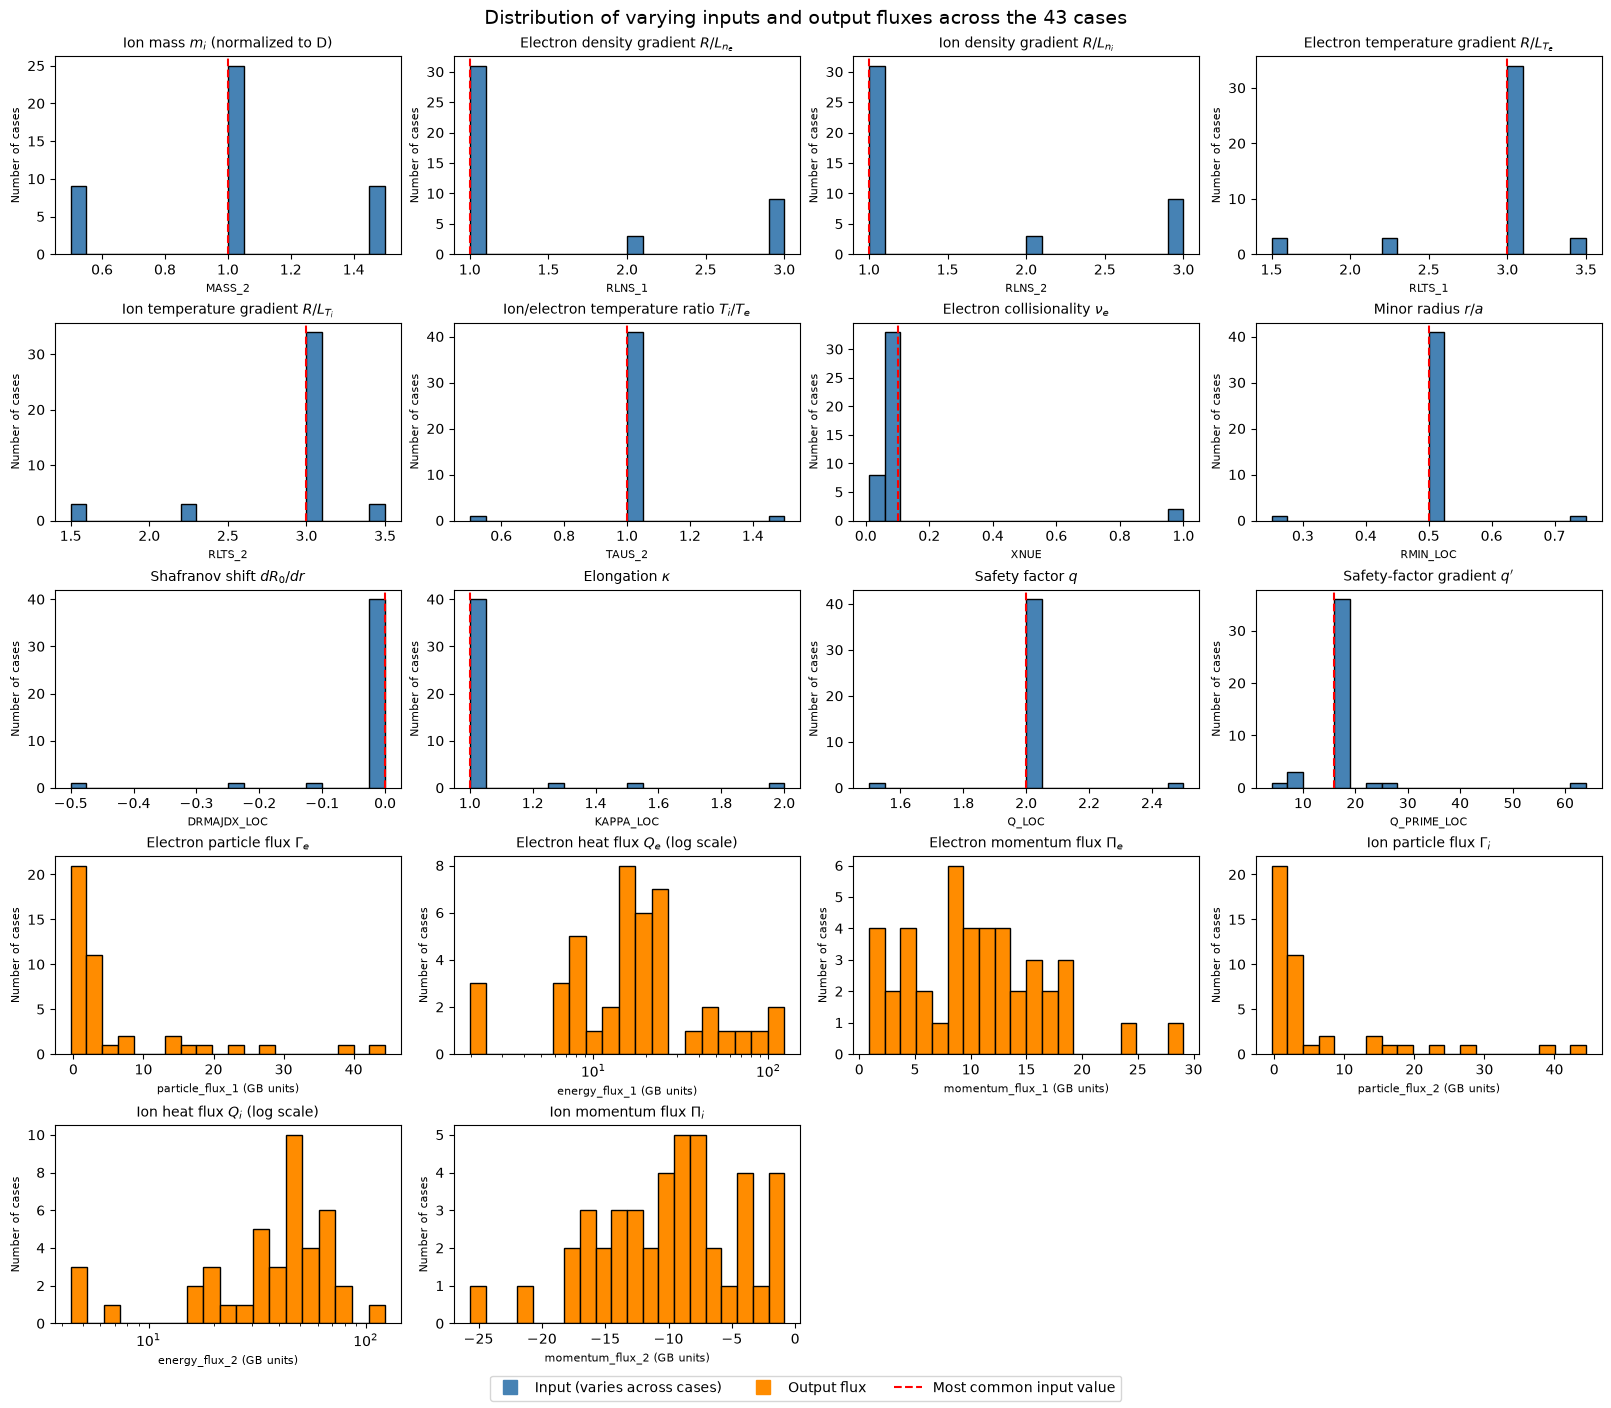

In [20]:
# step 4: plot summary statistics of all the features

# step 4.1: grab all the relevant columns (changed inputs + flux outputs) and make a filtered dataframe for plotting

y_variables = [c for c in df.columns if c.startswith(FLUX_PREFIXES)]
changed_variables = [c for c in all_changed.columns if c not in y_variables]
filtered_df = df[changed_variables + y_variables].copy()

# display names, so every plot uses the same wording for the same quantity (fluxes are in gyro-Bohm (GB) units)
X_LABELS = {
    "MASS_2": r"Ion mass $m_i$ (normalized to D)",
    "RLTS_1": r"Electron temperature gradient $R/L_{T_e}$",
    "RLTS_2": r"Ion temperature gradient $R/L_{T_i}$",
    "RLNS_1": r"Electron density gradient $R/L_{n_e}$",
    "RLNS_2": r"Ion density gradient $R/L_{n_i}$",
    "TAUS_2": r"Ion/electron temperature ratio $T_i/T_e$",
    "XNUE": r"Electron collisionality $\nu_e$",
    "RMIN_LOC": r"Minor radius $r/a$",
    "DRMAJDX_LOC": r"Shafranov shift $dR_0/dr$",
    "KAPPA_LOC": r"Elongation $\kappa$",
    "Q_LOC": r"Safety factor $q$",
    "Q_PRIME_LOC": r"Safety-factor gradient $q'$",
    "shear_scan": r"Magnetic shear $\hat{s}$",
}
FLUX_NAMES = {
    "particle_flux_1": r"Electron particle flux $\Gamma_e$",
    "particle_flux_2": r"Ion particle flux $\Gamma_i$",
    "energy_flux_1": r"Electron heat flux $Q_e$",
    "energy_flux_2": r"Ion heat flux $Q_i$",
    "momentum_flux_1": r"Electron momentum flux $\Pi_e$",
    "momentum_flux_2": r"Ion momentum flux $\Pi_i$",
}

# step 4.2: plot histograms for each varying input and output feature, with a vertical line for the most common value of that feature
# fluxes are orange (inputs blue), and energy fluxes get a log x-axis

cols = [c for c in deltas_df.columns if c in numeric_cols] + y_variables
fig, axes = plt.subplots(5, 4, figsize=(16, 14), constrained_layout=True)
for ax, col in zip(axes.flat, cols):
    s = df[col]
    is_flux = col.startswith(FLUX_PREFIXES)
    bins, log_axis = 20, col.startswith("energy_flux") and s.min() > 0
    if log_axis:
        bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 20)  # equal-width bins on a log axis
        ax.set_xscale("log")
    ax.hist(s, bins=bins, color="darkorange" if is_flux else "steelblue", edgecolor="black")
    if col in most_common.index:
        ax.axvline(most_common[col], color="red", linestyle="--")
    ax.set_title(FLUX_NAMES.get(col, X_LABELS.get(col, col)) + (" (log scale)" if log_axis else ""), fontsize=10)
    ax.set_xlabel(f"{col} (GB units)" if is_flux else col, fontsize=8)
    ax.set_ylabel("Number of cases", fontsize=8)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
fig.legend(handles=[
    plt.Line2D([], [], color="steelblue", marker="s", linestyle="", markersize=10, label="Input (varies across cases)"),
    plt.Line2D([], [], color="darkorange", marker="s", linestyle="", markersize=10, label="Output flux"),
    plt.Line2D([], [], color="red", linestyle="--", label="Most common input value"),
], loc="outside lower center", ncol=3)
fig.suptitle(f"Distribution of varying inputs and output fluxes across the {len(df)} cases", fontsize=14)
plt.show()

### Correlations

A heatmap of the correlation between the varying inputs and the fluxes. `RLNS_2`, `RLTS_2` and `particle_flux_2` are left out because they equal `RLNS_1`, `RLTS_1` and `particle_flux_1`.

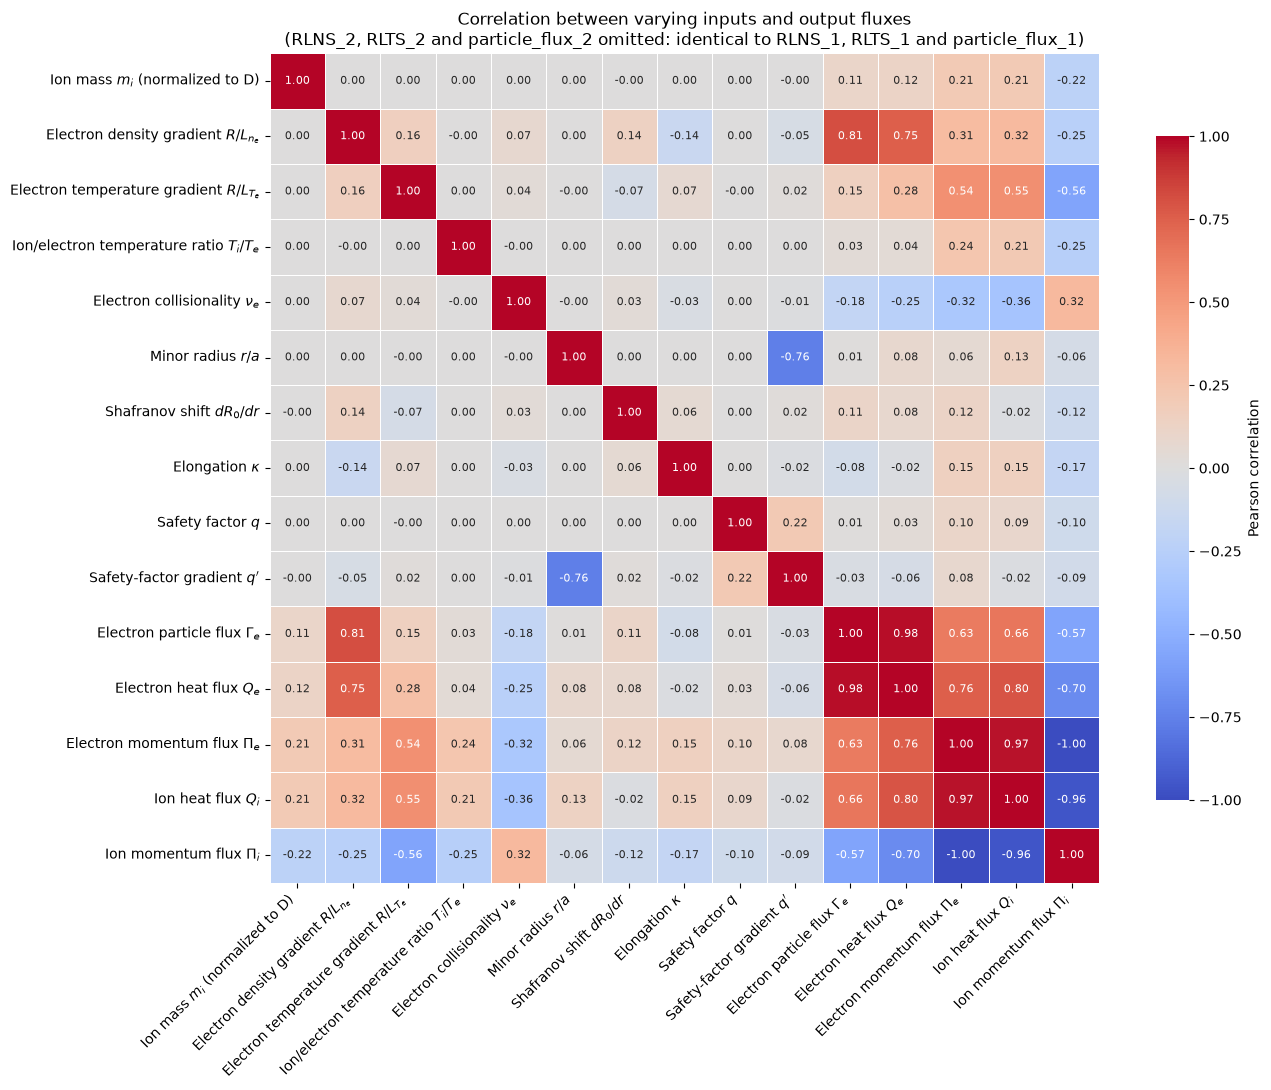

In [21]:
# step 4.3: correlation matrix of all varying inputs and outputs, with a heatmap

dupes = ["RLNS_2", "RLTS_2", "particle_flux_2"]  # identical to RLNS_1, RLTS_1 and particle_flux_1, so left out
heat_cols = [c for c in cols if c not in dupes]
corr = filtered_df[heat_cols].corr()
names = [FLUX_NAMES.get(c, X_LABELS.get(c, c)) for c in heat_cols]

plt.figure(figsize=(14, 11))
ax = sns.heatmap(
    corr, annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="coolwarm", vmin=-1, vmax=1, center=0,       # fixed scale so colours mean the same thing on every plot
    square=True, linewidths=0.5, linecolor="white",
    xticklabels=names, yticklabels=names,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.8},
)
ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_title("Correlation between varying inputs and output fluxes\n"
             "(RLNS_2, RLTS_2 and particle_flux_2 omitted: identical to RLNS_1, RLTS_1 and particle_flux_1)")
plt.tight_layout()
plt.show()

### Heat flux against temperature gradient

This cell defines `plot_flux_vs_drive`, which plots a flux against one input for H, D and T. Solid lines join the cases where only that input (and the isotope) changed. Faded dots are the cases where other inputs changed too. Here it plots ion and electron heat flux against the temperature gradient.

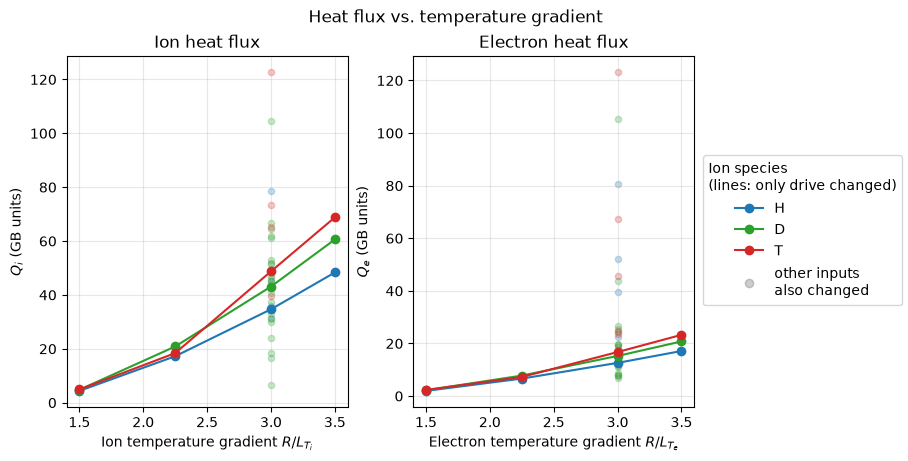

In [22]:
# step 4.4: heat flux vs. drive (temperature gradient), coloured by ion species
# Q_i (energy_flux_2) vs RLTS_2 (ion gradient) and Q_e (energy_flux_1) vs RLTS_1 (electron gradient)
ION_COLORS = {"H": "tab:blue", "D": "tab:green", "T": "tab:red"}

FLUX_LABELS = {  # short name -> (panel title, y-axis symbol); fluxes are in gyro-Bohm (GB) units
    "Q_i": ("Ion heat flux", r"$Q_i$"),
    "Q_e": ("Electron heat flux", r"$Q_e$"),
    "Gamma_e": ("Particle flux", r"$\Gamma_e$"),
    "Pi_i": ("Ion momentum flux", r"$\Pi_i$"),
}


def plot_flux_vs_drive(pairs, drive_cols, title, deltas=None):
    # deltas: table of how far each case is from the baseline, one column per varying input (default: deltas_df)
    deltas = deltas_df if deltas is None else deltas
    # "clean" scan = cases where nothing else changed except the drive (and the ion isotope);
    # the other cases also changed other inputs, so they are drawn faded
    other_inputs = [c for c in deltas.columns if c not in (*drive_cols, "MASS_2")]
    clean = (deltas[other_inputs].abs() < 1e-9).all(axis=1)

    fig, axes = plt.subplots(1, len(pairs), figsize=(max(4.5 * len(pairs), 8), 4.5), constrained_layout=True)
    for ax, (x, y, label) in zip(np.atleast_1d(axes), pairs):
        for ion, color in ION_COLORS.items():
            ion_df = df[df["species_type_2"] == ion]
            is_clean = clean[ion_df.index]
            ax.scatter(ion_df.loc[~is_clean, x], ion_df.loc[~is_clean, y], color=color, alpha=0.25, s=20)
            scan = ion_df[is_clean].sort_values(x)
            ax.plot(scan[x], scan[y], "o-", color=color)
        name, symbol = FLUX_LABELS.get(label, (label, label))
        if len(pairs) > 1:
            ax.set_title(name)
        ax.set_xlabel(X_LABELS.get(x, x))
        ax.set_ylabel(f"{symbol} (GB units)" if len(pairs) > 1 else f"{name} {symbol} (GB units)")
        ax.grid(True, alpha=0.3)
    # one legend for the whole figure: lines = clean scan per ion species, faded dots = other cases
    handles = [plt.Line2D([], [], color=c, marker="o", label=ion) for ion, c in ION_COLORS.items()]
    handles.append(plt.Line2D([], [], color="grey", marker="o", linestyle="", alpha=0.4, label="other inputs\nalso changed"))
    fig.legend(handles=handles, title="Ion species\n(lines: only drive changed)", loc="outside right center")
    fig.suptitle(title)
    plt.show()


plot_flux_vs_drive(
    pairs=[("RLTS_2", "energy_flux_2", "Q_i"), ("RLTS_1", "energy_flux_1", "Q_e")],
    drive_cols=("RLTS_1", "RLTS_2"),
    title="Heat flux vs. temperature gradient",
)

### Particle flux against density gradient

The same plot for the particle flux and the density gradient. `particle_flux_2` is identical to `particle_flux_1`, so only one is drawn.

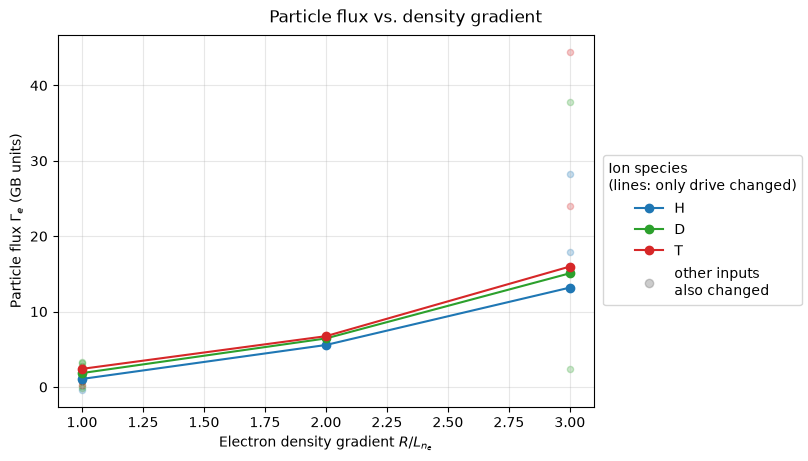

In [23]:
# step 4.5: particle flux vs. density gradient (RLNS = R/L_n), coloured by ion species
# the drive on the x-axis is the density gradient: Gamma_e (particle_flux_1) vs RLNS_1 (electron density gradient)
# (particle_flux_2 is identical to particle_flux_1 in this data, so only one is plotted)
plot_flux_vs_drive(
    pairs=[("RLNS_1", "particle_flux_1", "Gamma_e")],
    drive_cols=("RLNS_1", "RLNS_2"),
    title="Particle flux vs. density gradient",
)

### Ion mass

Ion heat flux against ion mass for each experiment that has all three isotopes. In seven of the eight, the flux rises from H to D to T. Experiment `c` is the exception.

8 letters have H, D and T: ['a', 'b', 'c', 'd', 'e', 'f', 'j', 'x']


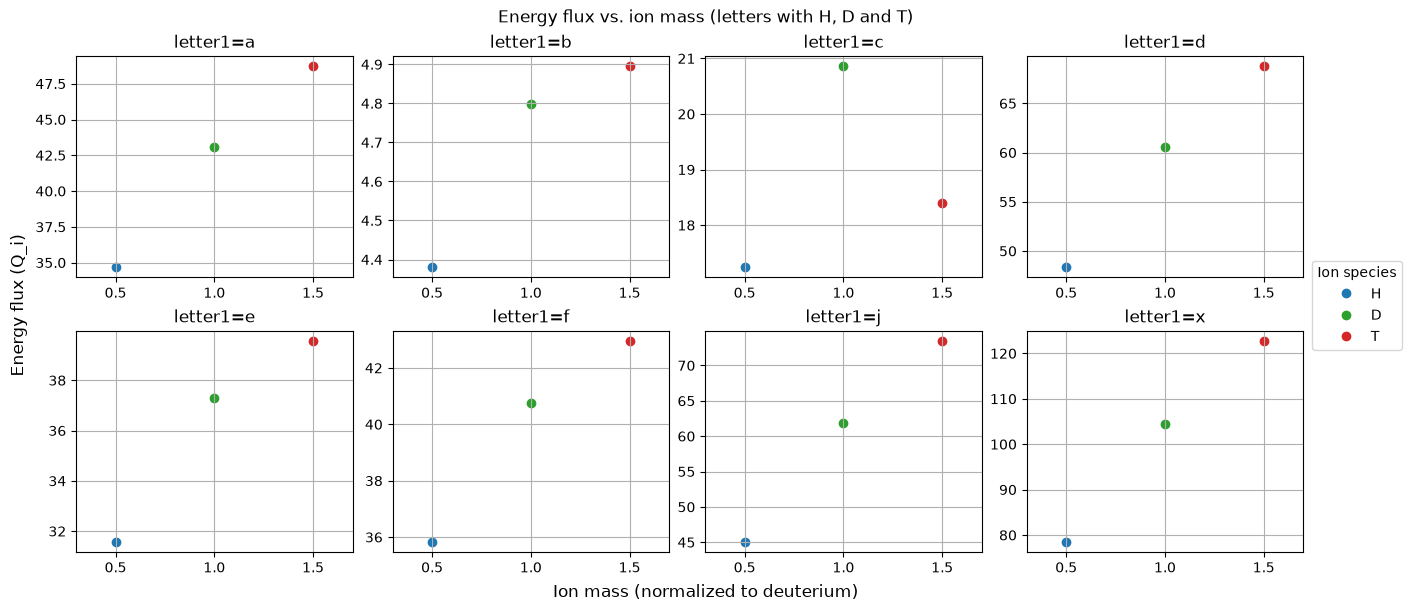

In [24]:
# step 4.6: for each <letter_1>, plot the calculated energy fluxes of the three ion species (H, D, T) against ion mass
# one panel per letter1, all in one figure (grid); only letters that have all three ion species present

ions_per_letter = df.groupby("letter1")["species_type_2"].agg(set)
letters = sorted(ions_per_letter[ions_per_letter.apply(lambda s: s >= set(ION_COLORS))].index)
print(f"{len(letters)} letters have H, D and T: {letters}")

ncols = 4
nrows = int(np.ceil(len(letters) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 3 * nrows), constrained_layout=True)
for ax, letter1 in zip(np.atleast_1d(axes).flat, letters):
    group = df[df["letter1"] == letter1]
    for ion, color in ION_COLORS.items():
        ion_df = group[group["species_type_2"] == ion]
        ax.scatter(ion_df["MASS_2"], ion_df["energy_flux_2"], color=color, label=ion)
    ax.set_xticks([0.5, 1.0, 1.5])
    ax.set_xlim(0.3, 1.7)
    ax.set_title(f"letter1={letter1}")
    ax.grid(True)
for ax in np.atleast_1d(axes).flat[len(letters):]:
    ax.axis("off")
fig.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color=c, label=ion) for ion, c in ION_COLORS.items()],
           title="Ion species", loc="outside right center")
fig.supxlabel("Ion mass (normalized to deuterium)")
fig.supylabel("Energy flux (Q_i)")
fig.suptitle("Energy flux vs. ion mass (letters with H, D and T)")
plt.show()

### Experiment c

The H and T fluxes divided by the D flux at each temperature gradient. For ion heat flux, the T ratio is 0.88 at a gradient of 2.25 (experiment `c`) and between 1.02 and 1.14 at the other gradients. The other fluxes show the same dip. The H ratio declines smoothly.

Q_i relative to D (1.0 = same as deuterium):
species_type_2      H      T experiment
RLTS                                   
1.50            0.913  1.020          b
2.25            0.826  0.882          c
3.00            0.804  1.131          a
3.50            0.798  1.135          d


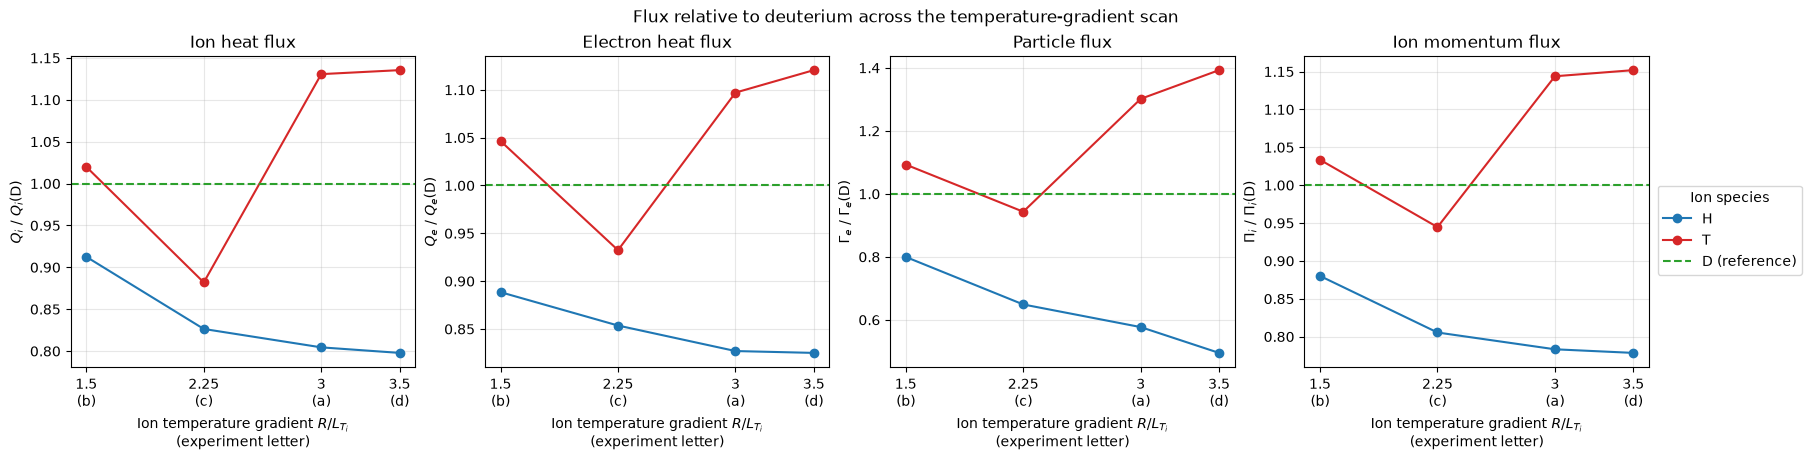

In [25]:
# step 4.6b: is experiment c the odd one out? flux of the H and T runs relative to D at each temperature gradient
# dividing by the D value removes the overall rise of flux with gradient, so only the isotope effect is left

# the temperature-gradient scan = cases where only RLTS (and the isotope) changed from the baseline
other_inputs = [c for c in deltas_df.columns if c not in ("RLTS_1", "RLTS_2", "MASS_2")]
scan = df[(deltas_df[other_inputs].abs() < 1e-9).all(axis=1)]
letter_at = scan.groupby("RLTS_2")["letter1"].first()   # gradient -> experiment letter

FLUX_ROWS = [("energy_flux_2", "Q_i"), ("energy_flux_1", "Q_e"), ("particle_flux_1", "Gamma_e"), ("momentum_flux_2", "Pi_i")]
ratios = {}
for flux, label in FLUX_ROWS:
    table = scan.pivot_table(index="RLTS_2", columns="species_type_2", values=flux).dropna()  # gradients with H, D and T
    ratios[label] = table[["H", "T"]].div(table["D"], axis=0)
print("Q_i relative to D (1.0 = same as deuterium):")
print(ratios["Q_i"].rename_axis("RLTS").assign(experiment=letter_at).round(3))

fig, axes = plt.subplots(1, len(FLUX_ROWS), figsize=(4.5 * len(FLUX_ROWS), 4.5), constrained_layout=True, sharex=True)
for ax, (flux, label) in zip(axes, FLUX_ROWS):
    r = ratios[label]
    for ion in ("H", "T"):
        ax.plot(r.index, r[ion], "o-", color=ION_COLORS[ion])
    ax.axhline(1.0, color=ION_COLORS["D"], linestyle="--")
    name, symbol = FLUX_LABELS[label]
    ax.set_title(name)
    ax.set_ylabel(f"{symbol} / {symbol}(D)")
    ax.set_xticks(r.index, [f"{g:g}\n({letter_at[g]})" for g in r.index])
    ax.set_xlabel(X_LABELS["RLTS_2"] + "\n(experiment letter)")
    ax.grid(True, alpha=0.3)
fig.legend(handles=[plt.Line2D([], [], color=ION_COLORS[i], marker="o", label=i) for i in ("H", "T")]
           + [plt.Line2D([], [], color=ION_COLORS["D"], linestyle="--", label="D (reference)")],
           title="Ion species", loc="outside right center")
fig.suptitle("Flux relative to deuterium across the temperature-gradient scan")
plt.show()

### Momentum flux against geometry inputs

Ion momentum flux against minor radius, Shafranov shift and elongation, with the most common value of each input marked in red.

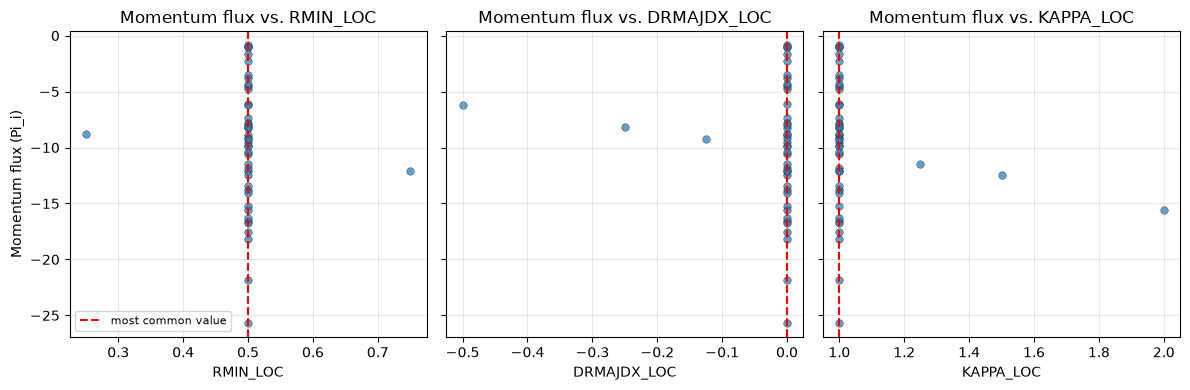

In [26]:
# step 4.7: graph RMIN_LOC, the minor radius r/a, DRMAJDX_LOC, the derivative of the major radius, and KAPPA_LOC, the plasma shape parameter, against momentum flux (Pi_i = momentum_flux_2), by ZS (ion charge)

x_cols = ["RMIN_LOC", "DRMAJDX_LOC", "KAPPA_LOC"]
y_col = "momentum_flux_2"

fig, axes = plt.subplots(1, len(x_cols), figsize=(12, 4), sharey=True)
for ax, col in zip(axes, x_cols):
    ax.scatter(df[col], df[y_col], s=30, alpha=0.7, edgecolor="black", linewidth=0.3)
    ax.axvline(most_common[col], color="red", linestyle="--", label="most common value")
    ax.set_xlabel(col)
    ax.set_title(f"Momentum flux vs. {col}")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Momentum flux (Pi_i)")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

### Heat flux against the temperature ratio

Ion and electron heat flux against `TAUS_2`, the ion to electron temperature ratio, using the same plot function.

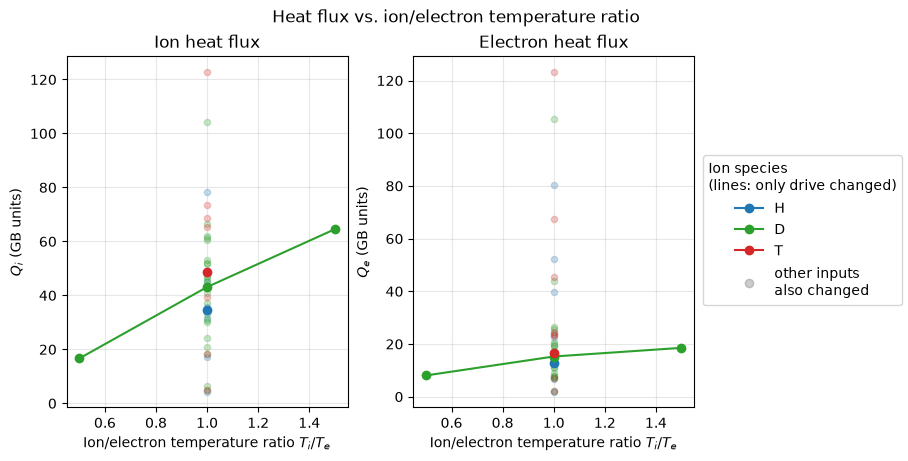

In [27]:
# step 4.6: heat flux vs. TAUS_2 (T_i / T_e), coloured by ion species
plot_flux_vs_drive(
    pairs=[("TAUS_2", "energy_flux_2", "Q_i"), ("TAUS_2", "energy_flux_1", "Q_e")],
    drive_cols=("TAUS_2",),
    title="Heat flux vs. ion/electron temperature ratio",
)

### Magnetic shear

`Q_PRIME_LOC` depends on the safety factor, the minor radius and the shear together, so some experiments change it along with `Q_LOC` or `RMIN_LOC`. This cell computes the shear itself and builds `deltas_phys`, where each geometry experiment changes exactly one input.

In [28]:
# step 4.8: derive the magnetic shear. Q_PRIME_LOC mixes q, r/a and the shear (Q_PRIME_LOC = shear * q^2 / r^2),
# so some scans change it together with Q_LOC or RMIN_LOC. replace it with the independent coordinate (shear) to get clean one-parameter scans
df["shear_scan"] = df["Q_PRIME_LOC"] * df["RMIN_LOC"]**2 / df["Q_LOC"]**2
baseline_shear = most_common["Q_PRIME_LOC"] * most_common["RMIN_LOC"]**2 / most_common["Q_LOC"]**2
deltas_phys = deltas_df.drop(columns="Q_PRIME_LOC").assign(shear_scan=df["shear_scan"] - baseline_shear)
print("varying inputs (Q_PRIME_LOC replaced by shear_scan):", deltas_phys.columns.tolist())

varying inputs (Q_PRIME_LOC replaced by shear_scan): ['MASS_2', 'RLNS_1', 'RLNS_2', 'RLTS_1', 'RLTS_2', 'TAUS_2', 'XNUE', 'RMIN_LOC', 'DRMAJDX_LOC', 'KAPPA_LOC', 'Q_LOC', 'shear_scan']


### Flux against geometry

All four fluxes against magnetic shear, safety factor and minor radius, with one figure per input.

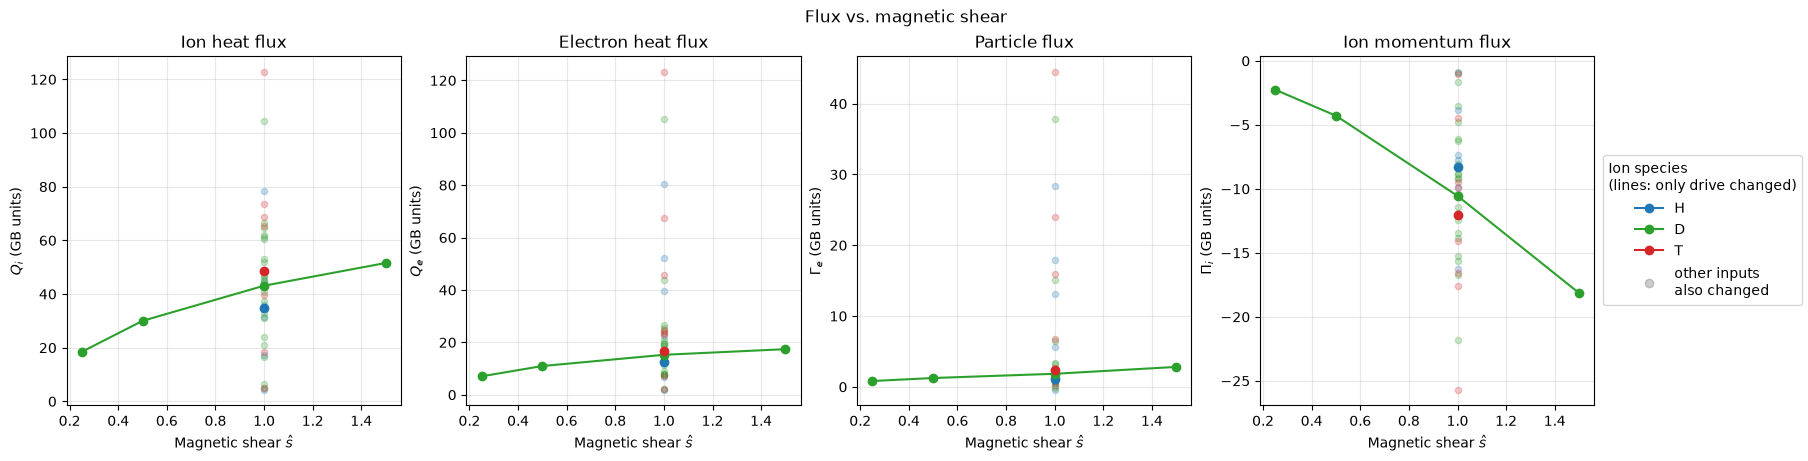

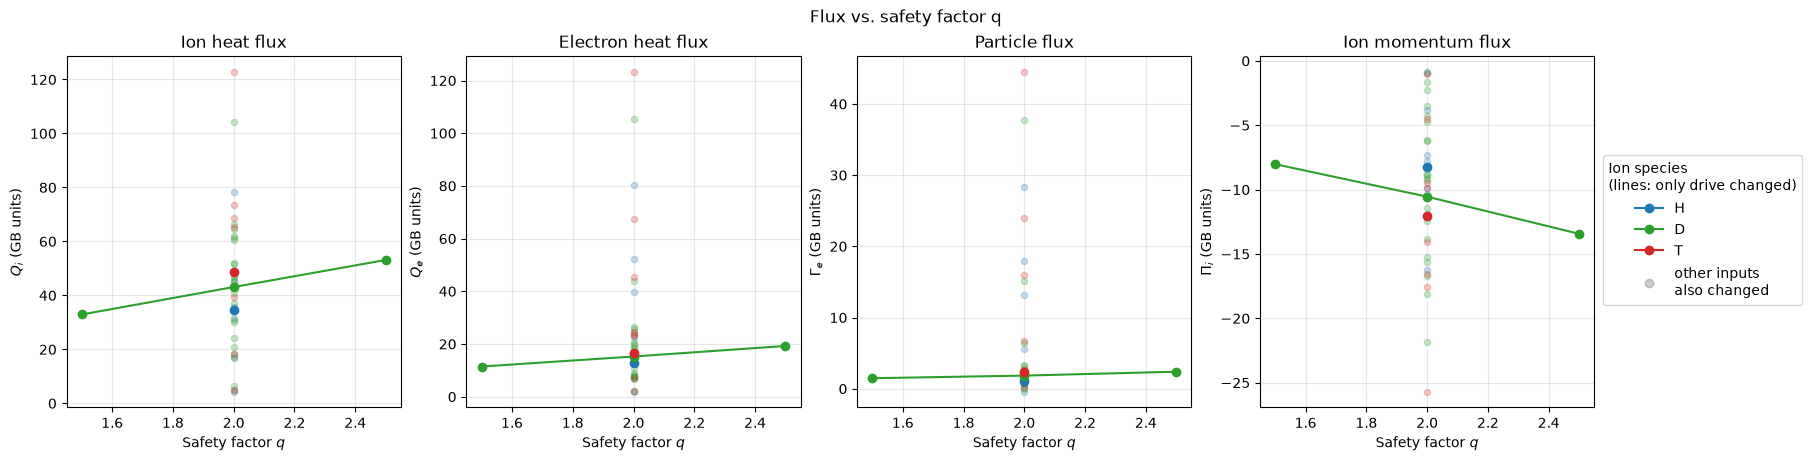

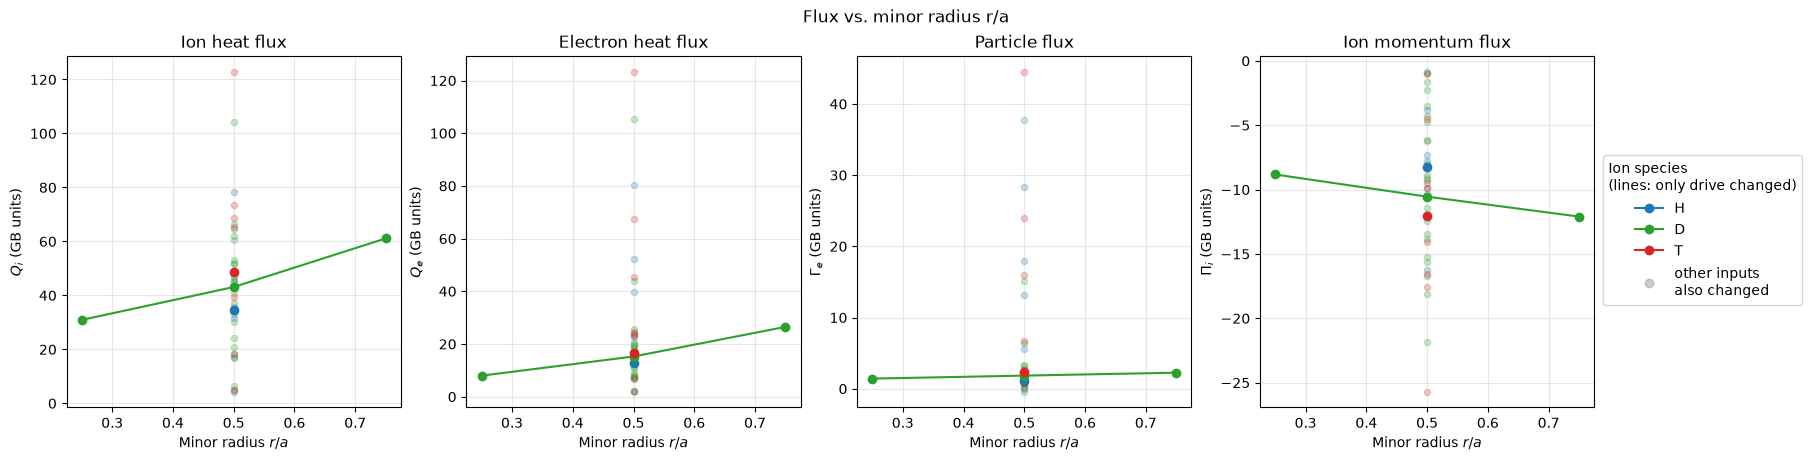

In [29]:
# step 4.9: flux vs. magnetic geometry, coloured by ion species. each scan changes exactly one of
# magnetic shear (shear_scan), safety factor q (Q_LOC) or minor radius r/a (RMIN_LOC); the other inputs stay at baseline
FLUXES = [("energy_flux_2", "Q_i"), ("energy_flux_1", "Q_e"), ("particle_flux_1", "Gamma_e"), ("momentum_flux_2", "Pi_i")]

for drive, name in [("shear_scan", "magnetic shear"), ("Q_LOC", "safety factor q"), ("RMIN_LOC", "minor radius r/a")]:
    plot_flux_vs_drive(
        pairs=[(drive, y, label) for y, label in FLUXES],
        drive_cols=(drive,),
        deltas=deltas_phys,
        title=f"Flux vs. {name}",
    )

### Data quality

Checks for missing or infinite values, non-positive heat flux, flux outliers, and inputs far from every other case. Each flagged case is listed with the inputs it changed. Two cases have an inward (negative) particle flux, and the outliers trace back to extreme inputs.

In [30]:
# step 4.10: data quality: look for anything suspicious (non-finite values, non-positive heat flux, outliers, isolated inputs)
reasons, checked = {}, []   # reasons: case -> list of reasons it was flagged; checked: every check that was run


def flag(mask, reason):
    if reason not in checked:
        checked.append(reason)
    for case in df.index[mask]:
        reasons.setdefault(case, []).append(reason)


def robust_z(s):  # modified z-score from the median and MAD; |z| > 3.5 is the usual outlier cutoff
    mad = (s - s.median()).abs().median()
    return 0.6745 * (s - s.median()) / mad if mad > 0 else s * 0


# 1. values that are missing or unusable
flag(~np.isfinite(df.select_dtypes("number")).all(axis=1), "NaN or infinite value")

# 2. physically suspicious signs
flag((df["energy_flux_1"] <= 0) | (df["energy_flux_2"] <= 0), "zero or negative heat flux")
flag(df["particle_flux_1"] < 0, "negative (inward) particle flux")
flag(~np.isclose(df["particle_flux_1"], df["particle_flux_2"], rtol=1e-2, atol=1e-9), "electron and ion particle flux differ")

# 3. extreme outliers in each output (on a log scale when the flux is always positive)
for col in [c for c in y_variables if c != "particle_flux_2"]:   # particle_flux_2 is identical to particle_flux_1
    s = df[col]
    flag(robust_z(np.log10(s) if (s > 0).all() else s).abs() > 3.5, f"outlier in {col}")

# 4. inputs far from the rest: distance to the nearest other case in min-max scaled input space
inputs = df[deltas_phys.columns].astype(float)
scaled = (inputs - inputs.min()) / (inputs.max() - inputs.min())
dist = np.sqrt(((scaled.values[:, None, :] - scaled.values[None, :, :]) ** 2).sum(axis=-1))
np.fill_diagonal(dist, np.inf)
nearest = pd.Series(dist.min(axis=1), index=df.index)
flag(nearest > 2 * nearest.median(), "inputs far from every other case")

quality_report = pd.DataFrame({
    "cases flagged": [sum(r in rs for rs in reasons.values()) for r in checked],
    "cases": [", ".join(c for c, rs in reasons.items() if r in rs) or "-" for r in checked],
}, index=pd.Index(checked, name="check"))
print(f"parse failures: {len(failures_df)}")
print(quality_report.to_string())
mom_sum = (df["momentum_flux_1"] + df["momentum_flux_2"]).abs() / df["momentum_flux_2"].abs()
print(f"info: electron and ion momentum flux nearly cancel (|Pi_e + Pi_i| / |Pi_i| is at most {mom_sum.max():.0%})")


def inputs_changed(case):
    row = deltas_phys.loc[case].drop("MASS_2")
    return "; ".join(f"{c} {v:+g}" for c, v in row.items() if abs(v) > 1e-9) or "(baseline)"


# for each flagged case, what did it change from the baseline? (an outlier whose inputs are extreme is explained, not a bad run)
flagged = pd.DataFrame({
    "ion": df.loc[list(reasons), "species_type_2"],
    "reasons": {c: "; ".join(rs) for c, rs in reasons.items()},
    "inputs changed from baseline": {c: inputs_changed(c) for c in reasons},
}).sort_index()
flagged

parse failures: 0
                                       cases flagged                                   cases
check                                                                                       
NaN or infinite value                              0                                       -
zero or negative heat flux                         0                                       -
negative (inward) particle flux                    2                                j_D, j_H
electron and ion particle flux differ              0                                       -
outlier in particle_flux_1                         8  f_D, f_H, f_T, x_D, x_H, x_T, y_H, y_T
outlier in energy_flux_1                           1                                     b_H
outlier in momentum_flux_1                         3                           b_H, b_D, b_T
outlier in energy_flux_2                           4                      b_H, b_D, b_T, z_D
outlier in momentum_flux_2                         0

,ion,reasons,inputs changed from baseline
b_D,D,outlier in momentum_flux_1; outlier in energy_...,RLTS_1 -1.5; RLTS_2 -1.5
b_H,H,outlier in energy_flux_1; outlier in momentum_...,RLTS_1 -1.5; RLTS_2 -1.5
b_T,T,outlier in momentum_flux_1; outlier in energy_...,RLTS_1 -1.5; RLTS_2 -1.5
f_D,D,outlier in particle_flux_1,RLNS_1 +2; RLNS_2 +2
f_H,H,outlier in particle_flux_1,RLNS_1 +2; RLNS_2 +2
f_T,T,outlier in particle_flux_1,RLNS_1 +2; RLNS_2 +2
j_D,D,negative (inward) particle flux,XNUE -0.09
j_H,H,negative (inward) particle flux,XNUE -0.09
k_D,D,inputs far from every other case,XNUE +0.9
x_D,D,outlier in particle_flux_1,RLNS_1 +2; RLNS_2 +2; XNUE -0.09


## Step 5: export the case table

Writes `data/sat3_tglf_table.csv`, with one row per case: readable column names, the varying inputs, the six fluxes and a `quality_flag` column. The flag is `ok`, or it lists why the case deserves a second look.

In [ ]:
# step 5: export one tidy table (one row per case) with readable column names and a quality-flag column
EXPORT_PATH = Path("data/sat3_tglf_table.csv")   # data/ holds the intermediary CSVs that are committed to git

READABLE = {
    "letter1": "experiment", "species_type_2": "ion_species", "MASS_2": "ion_mass",
    "RLTS_1": "electron_temp_gradient", "RLTS_2": "ion_temp_gradient",
    "RLNS_1": "electron_density_gradient", "RLNS_2": "ion_density_gradient",
    "TAUS_2": "ion_electron_temp_ratio", "XNUE": "electron_collisionality",
    "RMIN_LOC": "minor_radius", "DRMAJDX_LOC": "shafranov_shift", "KAPPA_LOC": "elongation",
    "Q_LOC": "safety_factor", "Q_PRIME_LOC": "q_prime", "shear_scan": "magnetic_shear",
    "particle_flux_1": "electron_particle_flux", "particle_flux_2": "ion_particle_flux",
    "energy_flux_1": "electron_heat_flux", "energy_flux_2": "ion_heat_flux",
    "momentum_flux_1": "electron_momentum_flux", "momentum_flux_2": "ion_momentum_flux",
}
meta_cols = ["letter1", "species_type_2"]
input_names = [c for c in [*deltas_df.columns, "shear_scan"] if c in df.columns]   # inputs that vary across cases
flux_names = [c for c in df.columns if c.startswith(FLUX_PREFIXES)]
table = df[meta_cols + list(dict.fromkeys(input_names)) + flux_names].rename(columns=READABLE)


# quality flag: "ok", or the reasons a case deserves a second look (several reasons are joined with "; ")
def quality_flags(row):
    flags = []
    fluxes = row[[READABLE[c] for c in flux_names]].astype(float)
    if not np.isfinite(fluxes).all():
        flags.append("non-finite flux")
    if row["electron_heat_flux"] <= 0 or row["ion_heat_flux"] <= 0:
        flags.append("non-positive heat flux")
    if not np.isclose(row["electron_particle_flux"], row["ion_particle_flux"], rtol=1e-2, atol=1e-9):
        flags.append("electron and ion particle flux differ")
    if row["electron_particle_flux"] < 0:
        flags.append("inward (negative) particle flux")
    return flags


flags = table.apply(quality_flags, axis=1)

# a heavier isotope with a lower ion heat flux than the next-lighter isotope of the same experiment (e.g. c_T < c_D)
for experiment, group in table.groupby("experiment"):
    ordered = group.sort_values("ion_mass")
    for lighter, heavier in zip(ordered.index[:-1], ordered.index[1:]):
        if ordered.loc[heavier, "ion_heat_flux"] < ordered.loc[lighter, "ion_heat_flux"]:
            flags[heavier] = flags[heavier] + ["heat flux lower than lighter isotope"]

table["quality_flag"] = flags.apply(lambda f: "; ".join(f) if f else "ok")
table.index.name = "case"

EXPORT_PATH.parent.mkdir(exist_ok=True)
table.to_csv(EXPORT_PATH)
print(f"wrote {EXPORT_PATH} with {len(table)} rows and {table.shape[1] + 1} columns (including the case index)")
print(table["quality_flag"].value_counts().to_string())
table[table["quality_flag"] != "ok"]

## Step 6: summarize the experiments

Builds one row per experiment letter that says which inputs it changed and by how much, and writes it to `data/sat3_experiments.csv`.

In [ ]:
# step 6: experiment summary table (letter -> parameters changed), built directly from the data
# the isotope (MASS_2) is not a scanned parameter, so it is left out; Q_PRIME_LOC is replaced by the magnetic shear (step 4.8)
EXPERIMENTS_PATH = Path("data/sat3_experiments.csv")   # data/ holds the intermediary CSVs that are committed to git

scanned = [c for c in deltas_phys.columns if c != "MASS_2"]
baseline = most_common[[c for c in scanned if c != "shear_scan"]].astype(float)
baseline["shear_scan"] = baseline_shear

rows = []
for letter, cases in df.groupby("letter1"):
    changed = [c for c in scanned if (deltas_phys.loc[cases.index, c].abs() > 1e-9).any()]
    # parameters that always move together to the same values (e.g. RLTS_1 and RLTS_2) are listed as one change
    groups = {}
    for c in changed:
        series = tuple(df.loc[cases.index, c].round(6))
        groups.setdefault((baseline[c], series), []).append(c)
    names = ["; ".join(" & ".join(READABLE.get(c, c) for c in cols) for cols in groups.values())]
    new_values = []
    for (base, series), cols in groups.items():
        new_values.append(f"{base:g} -> {', '.join(f'{v:g}' for v in sorted(set(series)))}")
    ions = cases.sort_values("MASS_2")["species_type_2"]
    rows.append({
        "experiment": letter,
        "ions": ", ".join(ions),
        "parameters changed": names[0] or "(none: baseline)",
        "baseline -> new value": "; ".join(new_values) or "-",
    })

experiments_df = pd.DataFrame(rows).set_index("experiment")
EXPERIMENTS_PATH.parent.mkdir(exist_ok=True)
experiments_df.to_csv(EXPERIMENTS_PATH)
print(f"wrote {EXPERIMENTS_PATH} with {len(experiments_df)} rows")
experiments_df